# Run SDM for Snowdon Beetle (*Chrysolina cerealis*): Random Forest

*Section 11 — Case study: species distribution modelling, notebook 4 of 5.* Previous: `03_maxent_species_distribution_modelling`. Next: `05_compare_sdm_models`.

This notebook models the Snowdon beetle a third time, with a **random forest**, the model used in the rsgispy species distribution modelling guide, again with the same training data as notebooks 02 and 03. Notebook 05 compares the three models.

**What a random forest is.** A random forest is an ensemble of classification trees. Each tree repeatedly splits the samples on a threshold of one variable (e.g. "distance to ledges < 640 m") so that the groups it creates are as pure as possible (mostly presences, or mostly pseudo-absences). Each tree is grown on a bootstrap sample of the training data and considers only a random subset of the variables at each split; the forest's prediction is the average of its trees. Compared with the other two models:

* **Responses can take any shape**, without us choosing features (no quadratic term, no hinges): but they are **step-like** (the average of many step functions), and **flat beyond the training data**, since a tree cannot split outside the range it has seen.
* **Interactions are found automatically**: a tree that first splits on temperature and then on distance to ledges represents an interaction. This flexibility is also the main risk: with few presences, a random forest can learn the exact locations of the training sites (over-fitting), which random cross-validation does not detect.
* **No standardisation** is needed, and monotonic transformations of a variable (e.g. a logarithm of a distance) make no difference.
* **Class imbalance.** With many more pseudo-absences than presences, trees tend to predict "absent" everywhere. Barbet-Massin et al. (2012) recommend the same number of pseudo-absences as presences for tree models (often several replicate sets); here we keep the same training data as the other models, for a fair comparison, and weight the classes equally instead (`class_weight="balanced"`), as in the guide.

**You will learn:**
- how to fit and tune a random forest SDM (`min_samples_leaf`, `max_features`) with spatial cross-validation;
- why spatial cross-validation matters most for flexible models;
- how to interpret a random forest with response curves, jackknife importance, SHAP (`TreeExplainer`) and Sobol indices.

**Before you start:** run notebooks `01_prepare_datasets` and `02_species_distribution_modelling` (this notebook uses the training and test samples, and the scenario rasters, of notebook 02). Random forests are introduced in section 4 (`04_image_classification/03_supervised_pixel_classification`).

**Data:** from notebook 01: `outputs/Chrysolina_cerealis_presences.gpkg`, `outputs/valid_mask.tif`, `outputs/sdm_candidate_vars.json` and the images it lists. From notebook 02 (`outputs/sdm_LogReg_outs/`): `sdm_train.gpkg`, `sdm_test.gpkg` and the warmer temperature rasters `Mean_Winter_Temp_plus*.tif`.

**Run time:** about 5 minutes.

## Import Modules

In [1]:
import importlib.util
import os

import geopandas
import matplotlib.pyplot as plt
import numpy
import pandas
import rasterio
import rsgispy
import rsgispy.imagecalc.maths
import rsgispy.mapping.raster
import rsgispy.modelling.species_distribution as species_distribution
import rsgispy.tools.jsonio
import rsgispy.tools.plotting
from IPython.display import Image, display
from rsgispy.ml.cv import SpatialBlockKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

%matplotlib inline
pandas.set_option("display.max_columns", None)
pandas.set_option("display.width", 200)

## Define the Input Data and Output Directories

The same seven variables, the same training and test samples (with raw values), and the same spatial cross-validation as notebooks 02 and 03 (5 folds of 1 km blocks, repeated on five block grids for tuning).

In [2]:
out_dir = "outputs/sdm_RF_outs"
plots_dir = os.path.join(out_dir, "plots")
os.makedirs(plots_dir, exist_ok=True)
lr_dir = "outputs/sdm_LogReg_outs"

presences_vec_file = "outputs/Chrysolina_cerealis_presences.gpkg"
presences_vec_lyr = "presences"
valid_msk_img = "outputs/valid_mask.tif"
cand_var_imgs = rsgispy.tools.jsonio.read_json_to_dict("outputs/sdm_candidate_vars.json")
env_vars = dict()
for var_name, img_file in cand_var_imgs.items():
    env_vars[var_name] = species_distribution.EnvVarInfo(
        name=var_name, file=img_file, band=1, data_type=rsgispy.VAR_TYPE_CONTINUOUS
    )
analysis_vars = [var_name for var_name in env_vars if var_name != "elevation"]

train_gdf = geopandas.read_file(os.path.join(lr_dir, "sdm_train.gpkg"), layer="train")
test_gdf = geopandas.read_file(os.path.join(lr_dir, "sdm_test.gpkg"), layer="test")
test_y = test_gdf["clsid"].to_numpy()
n_train_pres = int(train_gdf["clsid"].sum())
train_pres_gdf = train_gdf[train_gdf["clsid"] == 1]
print("Training:", train_gdf["clsid"].value_counts().to_dict())
print("Test:    ", test_gdf["clsid"].value_counts().to_dict())

def repeated_block_splits(x_df, y, coords, block_sizes=(800, 900, 1000, 1100, 1200), n_splits=5):
    """5-fold spatial block CV repeated on several block grids: (train, validation) splits."""
    splits = []
    for blk_size in block_sizes:
        blk_cv = SpatialBlockKFold(n_splits=n_splits, block_size=float(blk_size), stratify=True, rnd_seed=42)
        splits += list(blk_cv.split(x_df, y, coords=coords))
    return splits


def boyce_scorer(estimator, x_df, y):
    """Boyce index of a fold's validation samples (a GridSearchCV scorer)."""
    probs = estimator.predict_proba(x_df)[:, 1]
    y = numpy.asarray(y)
    return species_distribution.calc_boyce_index(probs[y == 1], probs[y == 0])["boyce"]


# Score every fold by AUC and by the Boyce index; refit the highest mean AUC.
cv_scoring = {"auc": "roc_auc", "boyce": boyce_scorer}


def paired_one_se_table(search_obj, param_names):
    """
    Spatial CV AUC of each setting of a fitted GridSearchCV, with the mean
    difference from the best setting over the same folds and its standard
    error (paired SE); ``within_1se`` marks the settings not worse than the
    best by more than one paired SE. ``boyce_mean`` is the mean out-of-fold
    Boyce index (folds where it cannot be calculated are left out).
    """
    res = pandas.DataFrame(search_obj.cv_results_)
    n_folds = search_obj.n_splits_
    fold_auc = res[[f"split{k}_test_auc" for k in range(n_folds)]].to_numpy()
    fold_boyce = res[[f"split{k}_test_boyce" for k in range(n_folds)]].to_numpy()
    diff = fold_auc - fold_auc[int(numpy.argmax(fold_auc.mean(axis=1)))]
    out = pandas.DataFrame({new: res[f"param_{old}"] for old, new in param_names.items()})
    out["auc_mean"] = fold_auc.mean(axis=1)
    out["auc_sd"] = fold_auc.std(axis=1, ddof=1)
    out["diff_from_best"] = diff.mean(axis=1)
    out["diff_se"] = diff.std(axis=1, ddof=1) / numpy.sqrt(n_folds)
    out["within_1se"] = out["diff_from_best"] >= -out["diff_se"]
    out["boyce_mean"] = numpy.nanmean(fold_boyce, axis=1)
    return out


blk_cv = SpatialBlockKFold(n_splits=5, block_size=1000.0, stratify=True, rnd_seed=42)
train_xy = numpy.column_stack([train_gdf.geometry.x, train_gdf.geometry.y])
blk_splits = list(blk_cv.split(train_gdf[analysis_vars], train_gdf["clsid"], coords=train_xy))
print("Presences in each held-out fold (1 km blocks):",
      [int(train_gdf["clsid"].iloc[test_idx].sum()) for _, test_idx in blk_splits])
tune_splits = repeated_block_splits(train_gdf[analysis_vars], train_gdf["clsid"], train_xy)

Training: {0: 7000, 1: 23}
Test:     {0: 3000, 1: 11}
Presences in each held-out fold (1 km blocks): [9, 4, 3, 4, 3]


## 1. Tune the Random Forest

Two hyperparameters control how closely a random forest follows the training data:

* `min_samples_leaf`: the minimum number of samples in a leaf (end node) of a tree. With 1, a tree can isolate a single presence, i.e. memorise a site; larger values give smoother, more general responses. Ecologically, it sets how many records must share a combination of conditions before the forest believes it.
* `max_features`: the number of variables a split may choose from (`"sqrt"`: 2–3 of the 7; `1.0`: all). Fewer variables make the trees more different from each other, and let weaker variables be used.

We use 500 trees (more only make the result more stable, not more flexible), and tune with the same 25 spatial splits and the same rule as notebooks 02 and 03: the settings within one paired standard error of the best spatial cross-validated AUC are accepted, and the one with the highest out-of-fold Boyce index is chosen.

In [3]:
def make_rf_mdl(**params):
    return RandomForestClassifier(
        n_estimators=500, class_weight="balanced", n_jobs=-1, random_state=42, **params
    )


grid_space = {"min_samples_leaf": [1, 3, 10, 30, 100, 300], "max_features": ["sqrt", 1.0]}
search_obj = GridSearchCV(make_rf_mdl(), param_grid=grid_space, cv=tune_splits, scoring=cv_scoring, refit="auc")
search_obj.fit(train_gdf[analysis_vars], train_gdf["clsid"])
cv_res_df = paired_one_se_table(
    search_obj, {"min_samples_leaf": "min_samples_leaf", "max_features": "max_features"}
)

# As in notebooks 02 and 03: of the settings within one paired SE of the
# best AUC, the one with the highest out-of-fold Boyce index.
best_row = cv_res_df.loc[cv_res_df["auc_mean"].idxmax()]
ok_df = cv_res_df[cv_res_df["within_1se"]]
sel_row = ok_df.loc[ok_df["boyce_mean"].idxmax()]
print(f"Best AUC {best_row['auc_mean']:.3f} with min_samples_leaf {best_row['min_samples_leaf']}; "
      f"selected: min_samples_leaf {sel_row['min_samples_leaf']} with AUC {sel_row['auc_mean']:.3f} "
      f"({sel_row['diff_from_best']:+.4f}, paired SE {sel_row['diff_se']:.4f}), "
      f"out-of-fold Boyce {sel_row['boyce_mean']:.3f}")
cv_res_df.round(3)

/Users/pfb/miniconda3/envs/osgeo_gee_env_v6/lib/python3.14/site-packages/sklearn/model_selection/_search.py:1237: UserWarning: One or more of the test scores are non-finite: [ 0.12610282  0.25350833  0.34680808  0.38236028  0.39751646  0.30297829
 -0.24473744 -0.139209   -0.12278563 -0.03054684  0.251823           nan]
  warnings.warn(


Best AUC 0.917 with min_samples_leaf 300; selected: min_samples_leaf 100 with AUC 0.916 (-0.0009, paired SE 0.0038), out-of-fold Boyce 0.398


,min_samples_leaf,max_features,auc_mean,auc_sd,diff_from_best,diff_se,within_1se,boyce_mean
0,1,sqrt,0.759,0.166,-0.159,0.031,False,0.126
1,3,sqrt,0.833,0.129,-0.084,0.022,False,0.254
2,10,sqrt,0.895,0.070,-0.022,0.010,False,0.347
3,30,sqrt,0.905,0.058,-0.012,0.008,False,0.382
4,100,sqrt,0.916,0.053,-0.001,0.004,True,0.398
5,300,sqrt,0.917,0.040,0.000,0.000,True,0.303
6,1,1.0,0.665,0.156,-0.252,0.028,False,-0.245
7,3,1.0,0.721,0.164,-0.196,0.031,False,-0.139
8,10,1.0,0.809,0.133,-0.108,0.024,False,-0.123
9,30,1.0,0.869,0.125,-0.048,0.022,False,-0.031


Using only 2–3 variables per split (`max_features="sqrt"`) is clearly better than all 7 (0.76–0.92 against 0.67–0.88): it lets the weaker variables contribute and makes the trees less alike. Larger leaves help all the way: the AUC rises from 0.76 with fully grown trees (`min_samples_leaf` = 1, which memorise the training sites and are the most variable between folds) to 0.916 with leaves of 100 and 0.917 with leaves of 300. (The warning about non-finite scores is from the Boyce index of one setting, `min_samples_leaf` = 300 with all 7 variables, in folds where it could not be calculated; those folds are left out of its mean.)

Two settings are within one paired SE of the best: `min_samples_leaf` = 300 (the best AUC) and 100. Leaves of 300 samples give the smoothest forest, but they are large compared with 23 presences: such a forest predicts a broad plateau of similar suitability over large areas. Its out-of-fold Boyce index is lower (0.30 against 0.40), i.e. it ranks places *within* the suitable area less well, so the rule chooses `min_samples_leaf` = 100. The cell below compares the two candidates on the single 1 km split used for the ensemble:

In [4]:
cand_rows = {}
for label, row in [("best AUC", best_row), ("selected", sel_row)]:
    params = {"min_samples_leaf": int(row["min_samples_leaf"]), "max_features": row["max_features"]}
    _, scores_df = species_distribution.fit_kfold_sklearn_mdls(
        make_rf_mdl(**params), train_gdf, None, train_gdf, None, analysis_vars,
        cv=blk_cv, rnd_seed=42, return_scores=True, use_pbar=False,
    )
    cand_rows[f"{label}: min_samples_leaf {params['min_samples_leaf']}"] = (
        scores_df[["val_auc", "val_tss", "val_boyce"]].mean()
    )
pandas.DataFrame(cand_rows).round(3)

ROC: 0.9627329192546583 - 0.9706490683229814 - 0.9779875776397516
Train: 0.8699910952804987 - 0.8721509971509972 - 0.8831168831168831
Test: 0.8719920261996298 - 0.8744126441691584 - 0.8775452086003133
Validation (out-of-fold) ROC: 0.8863473909935667 - 0.9424631478839752 - 0.9618502622794469


ROC: 0.978664596273292 - 0.982388198757764 - 0.9850372670807452
Train: 0.8888888888888888 - 0.911759473403309 - 0.9352543578797581
Test: 0.8889363519863306 - 0.905595899188381 - 0.9278086287911149
Validation (out-of-fold) ROC: 0.8813438170121516 - 0.9539942938659058 - 0.9837068828485138


,best AUC: min_samples_leaf 300,selected: min_samples_leaf 100
val_auc,0.928,0.935
val_tss,0.871,0.859
val_boyce,0.509,0.601


On this split too the forest with leaves of 100 has a similar out-of-fold AUC and TSS to the forest with leaves of 300, and a higher Boyce index (0.60 against 0.51). This is a reminder not to tune on one measure alone. We use `min_samples_leaf` = 100 with `max_features="sqrt"`.

In [5]:
rf_params = {"min_samples_leaf": int(sel_row["min_samples_leaf"]), "max_features": sel_row["max_features"]}
rsgispy.tools.jsonio.write_dict_to_json(rf_params, os.path.join(out_dir, "rf_params.json"))
rf_params

{'min_samples_leaf': 100, 'max_features': 'sqrt'}

## 2. Fit and Evaluate the Model

The same evaluation as notebooks 02 and 03 on the same test points: AUC, TSS, Boyce index and a null-model test. The training AUC is also shown: for a flexible model, a training AUC near 1 with a much lower test or cross-validated AUC is the sign of over-fitting.

Classifier Train Score = 91.6%
Classifier Test Score = 91.9%
Training AUC: 0.989


auc                     0.981
threshold               0.489
tss                     0.918
sensitivity             1.000
specificity             0.918
omission_rate           0.000
commission_rate         0.082
kappa                   0.076
accuracy                0.918
balanced_accuracy       0.959
prevalence              0.004
n_presence             11.000
n_absence            3000.000
boyce                   0.427
null_p95                0.671
null_p_value            0.010
dtype: float64

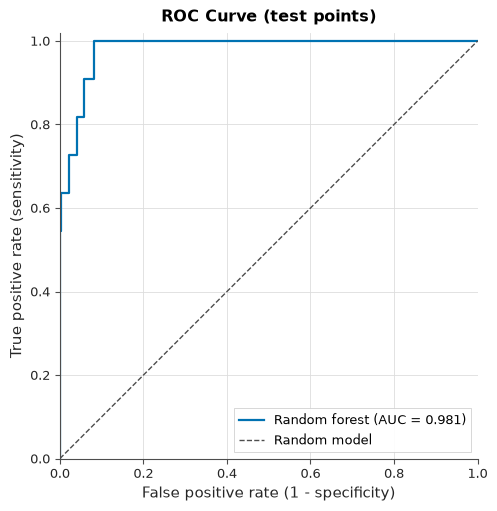

In [6]:
rf_mdl, train_acc, test_acc, test_auc = species_distribution.fit_sklearn_mdl(
    est_cls_obj=make_rf_mdl(**rf_params),
    train_vec_file=train_gdf,
    train_vec_lyr=None,
    test_vec_file=test_gdf,
    test_vec_lyr=None,
    analysis_vars=analysis_vars,
    cls_col="clsid",
    return_model=True,
)
train_probs = species_distribution.get_positive_class_probs(rf_mdl, train_gdf[analysis_vars])
train_fpr, train_tpr, train_auc = species_distribution.calc_binary_roc_auc(train_gdf["clsid"], train_probs)
print(f"Training AUC: {train_auc:.3f}")

test_probs = species_distribution.get_positive_class_probs(rf_mdl, test_gdf[analysis_vars])
rf_metrics = species_distribution.calc_sdm_eval_metrics(test_y, test_probs, bg_scores="absences")
fpr, tpr, auc = species_distribution.calc_binary_roc_auc(test_y, test_probs)
fig, ax = species_distribution.plot_roc_curve(
    fpr, tpr, auc, label="Random forest", title="ROC Curve (test points)",
    out_plot_file=os.path.join(plots_dir, "rf_testing_roc_curve.png"),
)
null_res = species_distribution.calc_null_model_auc(
    make_rf_mdl(**rf_params),
    train_gdf, None, test_gdf, None, analysis_vars,
    n_pres=n_train_pres, n_reps=99, observed_auc=rf_metrics["auc"], rnd_seed=42,
    plot_file=os.path.join(plots_dir, "rf_null_model_auc.png"), use_pbar=False,
)
rf_metrics["null_p95"] = null_res["null_p95"]
rf_metrics["null_p_value"] = null_res["p_value"]
pandas.Series(rf_metrics).round(3)

The random forest reaches a training AUC of 0.989: with leaves of at least 100 samples it cannot isolate single presences, but it still separates its own training presences from the background very well. On the test points it has an AUC of 0.981 (logistic regression 0.962, MaxEnt 0.987) and a TSS of 0.918, well above the null models (95th percentile 0.671, p = 0.01). But its Boyce index on the test points (0.427) is much lower than those of the logistic regression (0.896) and MaxEnt (0.768). And remember that the test points are a *random* sample of the same area, many of them a few hundred metres from training presences: exactly the situation in which a flexible model looks best. The next section checks this.

## 3. Random versus Spatial Cross-Validation

For a random forest the difference between random and spatial cross-validation is expected to be larger than for the logistic regression (notebook 02, section 11), because a forest can learn the exact conditions of the training sites, which nearby random held-out points share.

In [7]:
rnd_mdls, rnd_scores_df = species_distribution.fit_kfold_sklearn_mdls(
    make_rf_mdl(**rf_params),
    train_gdf, None, test_gdf, None, analysis_vars,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    rnd_seed=42, return_scores=True, use_pbar=False,
)
rf_mdls, rf_scores_df = species_distribution.fit_kfold_sklearn_mdls(
    make_rf_mdl(**rf_params),
    train_gdf, None, test_gdf, None, analysis_vars,
    cv=blk_cv, rnd_seed=42, return_scores=True, use_pbar=False,
)
score_cols = ["train_auc", "val_auc", "val_tss", "val_boyce", "test_auc", "test_tss"]
print(rf_scores_df[["fold", "n_train", "n_val"] + score_cols].round(3))
cv_cmp_df = pandas.DataFrame(
    {
        "random CV (mean)": rnd_scores_df[score_cols].mean(),
        "spatial CV (mean)": rf_scores_df[score_cols].mean(),
        "spatial CV (sd)": rf_scores_df[score_cols].std(),
    }
)
display(cv_cmp_df.round(3))

ens_test_probs = numpy.median(
    [species_distribution.get_positive_class_probs(mdl, test_gdf[analysis_vars]) for mdl in rf_mdls],
    axis=0,
)
rf_ens_metrics = species_distribution.calc_sdm_eval_metrics(test_y, ens_test_probs, bg_scores="absences")
pandas.Series(rf_ens_metrics).round(3)

ROC: 0.9746969696969696 - 0.9792727272727272 - 0.9804242424242424
Train: 0.8969384122463511 - 0.9033635878270155 - 0.9382342470630117
Test: 0.8990368648289605 - 0.9060112919295915 - 0.9349053470607771
Validation (out-of-fold) ROC: 0.8735714285714284 - 0.9708928571428572 - 0.9892857142857143


ROC: 0.970969696969697 - 0.9778181818181818 - 0.9817878787878789
Train: 0.8888888888888888 - 0.911759473403309 - 0.9352543578797581
Test: 0.8917303221521089 - 0.9076718698106941 - 0.9302557289936898
Validation (out-of-fold) ROC: 0.8813438170121516 - 0.9539942938659058 - 0.9837068828485138
   fold  n_train   n_val  train_auc  val_auc  val_tss  val_boyce  test_auc  test_tss
0     0   5616.0  1407.0      0.986    0.984    0.956      0.542     0.971     0.897
1     1   5615.0  1408.0      0.990    0.964    0.916      0.626     0.981     0.920
2     2   5618.0  1405.0      0.990    0.954    0.939      0.645     0.978     0.903
3     3   5622.0  1401.0      0.993    0.891    0.722      0.421     0.975     0.888
4     4   5621.0  1402.0      0.993    0.881    0.764      0.769     0.982     0.907


,random CV (mean),spatial CV (mean),spatial CV (sd)
train_auc,0.990,0.990,0.003
val_auc,0.944,0.935,0.046
val_tss,0.843,0.859,0.108
val_boyce,0.500,0.601,0.129
test_auc,0.979,0.977,0.005
test_tss,0.900,0.903,0.012


auc                     0.980
threshold               0.482
tss                     0.906
sensitivity             1.000
specificity             0.906
omission_rate           0.000
commission_rate         0.094
kappa                   0.066
accuracy                0.906
balanced_accuracy       0.953
prevalence              0.004
n_presence             11.000
n_absence            3000.000
boyce                   0.206
dtype: float64

With leaves of 100, the forest is much less over-fitted than a forest of fully grown trees: its members reach a training AUC of 0.990 and an out-of-fold AUC of 0.935 with spatial blocks (0.944 with random folds). The two members with the lowest out-of-fold scores reach an AUC of 0.88–0.89 (TSS 0.72–0.76), while their scores on the common, randomly chosen test set are 0.975–0.982: random test points flatter a forest. The spatial cross-validation estimates (AUC 0.94 ± 0.05, TSS 0.86) are the honest measure of how well it predicts at new sites, and they are as good as those of the logistic regression (0.93, 0.87) and MaxEnt (0.93, 0.87).

The ensemble's test scores are AUC 0.980, TSS 0.906 and Boyce index 0.21: on the test points, the median of five forests ranks presences against background very well, but hardly ranks them *within* the suitable area, because their median is a plateau of similar values.

In [8]:
resid_df = species_distribution.calc_residual_autocorrelation(
    rf_mdl, train_gdf, None, analysis_vars,
    dist_classes=[0, 250, 500, 1000, 1500, 2000, 3000, 4000, 6000],
    n_perms=99, rnd_seed=42,
)
resid_df[["dist_lower", "dist_upper", "morans_i", "p_value"]].round(3)

,dist_lower,dist_upper,morans_i,p_value
0,0.0,250.0,0.873,0.01
1,250.0,500.0,0.755,0.01
2,500.0,1000.0,0.569,0.01
3,1000.0,1500.0,0.368,0.01
4,1500.0,2000.0,0.240,0.01
5,2000.0,3000.0,0.084,0.01
6,3000.0,4000.0,-0.041,0.01
7,4000.0,6000.0,-0.054,0.01


The forest's residuals are a little less autocorrelated at short distances (Moran's I 0.87 below 250 m) than the logistic regression's (0.92), and more than those of the 20-feature MaxEnt model (0.68): the more closely a model follows the training samples, the less spatial structure is left in its residuals, whether or not it describes the habitat better. The autocorrelation still extends to about 3 km.

## 4. Interpreting the Random Forest

### 4.1 Response Curves

calc_grass_dist Range:	(0.0 - 6102.75341796875): Mean = 1280.7439933445144
Calculating Response Curve for 'calc_grass_dist'
flush_dist Range:	(0.0 - 2214.497802734375): Mean = 929.4367184846298
Calculating Response Curve for 'flush_dist'
impr_grass_dist Range:	(0.0 - 3739.732666015625): Mean = 1950.0651271654212
Calculating Response Curve for 'impr_grass_dist'
ledges_dist Range:	(0.0 - 5341.947265625): Mean = 355.9866565206776
Calculating Response Curve for 'ledges_dist'
rock_dist Range:	(0.0 - 6917.6005859375): Mean = 2436.267542300017
Calculating Response Curve for 'rock_dist'
scree_dist Range:	(0.0 - 3493.13623046875): Mean = 493.25894231381625
Calculating Response Curve for 'scree_dist'
winter_temp Range:	(2.5071563720703125 - 4.4408345222473145): Mean = 2.8537858465443486
Calculating Response Curve for 'winter_temp'


,variable,min suitability,max suitability,at value,>= half max from,to
0,calc_grass_dist,0.82,0.91,1533.36,0.00,6102.75
1,flush_dist,0.49,0.92,1057.17,0.00,2214.50
2,impr_grass_dist,0.60,0.92,1653.75,0.00,3739.73
3,ledges_dist,0.17,0.91,348.97,0.00,751.63
4,rock_dist,0.65,0.91,2641.90,0.00,6917.60
5,scree_dist,0.79,0.92,596.82,0.00,3493.14
6,winter_temp,0.33,0.91,2.75,2.51,3.05


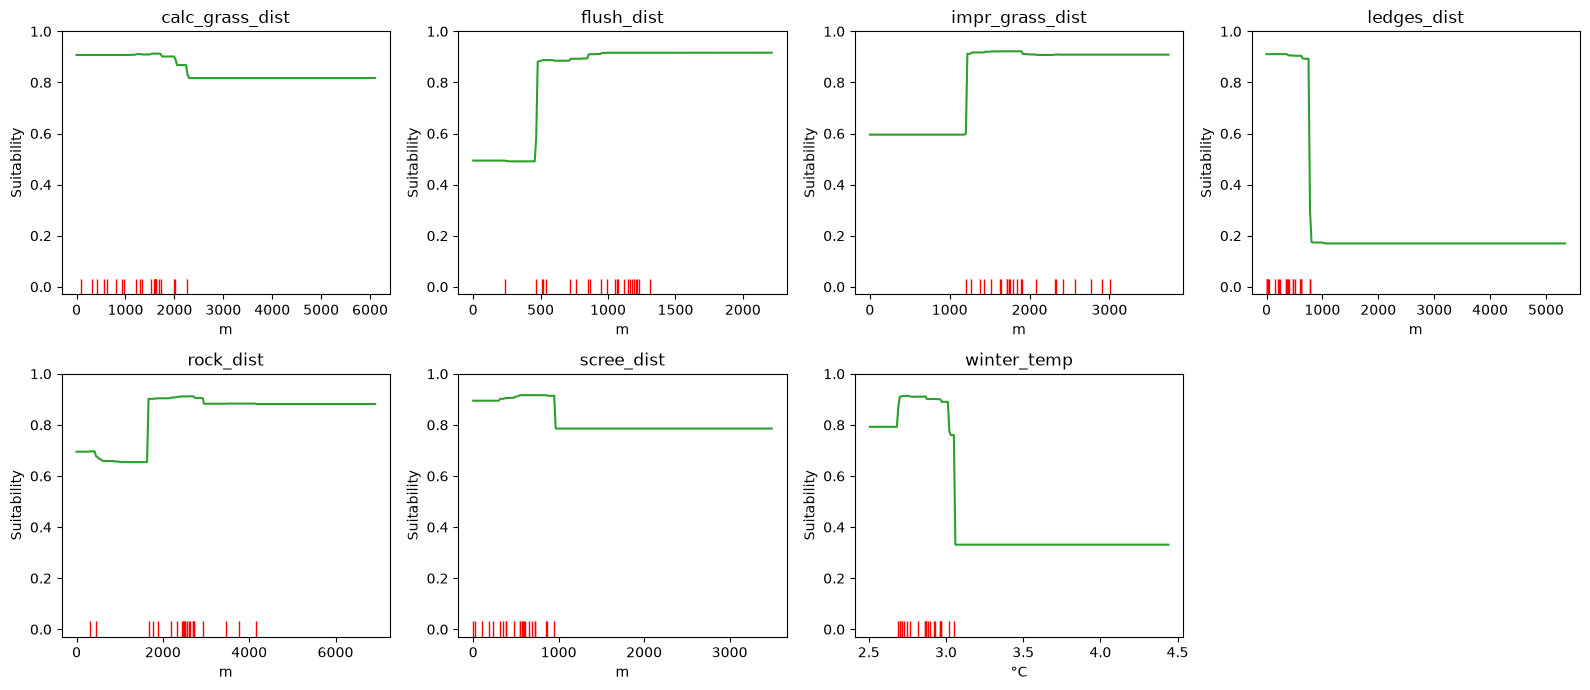

In [9]:
rf_resp_df = species_distribution.sklearn_mdl_variable_response_curves(
    est_cls_obj=rf_mdl,
    train_vec_file=train_gdf,
    train_vec_lyr=None,
    analysis_vars=analysis_vars,
    output_file=os.path.join(out_dir, "rf_response_curves.csv"),
    response_plots_dir=None,
    n_samples=200,
    cls_col="clsid",
)
units = {"winter_temp": "°C"}
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for ax, var_name in zip(axs.flatten(), analysis_vars):
    ax.plot(rf_resp_df[f"{var_name}_vals"], rf_resp_df[f"{var_name}_resp"], color="tab:green")
    ax.plot(train_pres_gdf[var_name], numpy.zeros(len(train_pres_gdf)), "|", color="red", ms=12)
    ax.set_ylim(-0.03, 1.0)
    ax.set_title(var_name)
    ax.set_xlabel(units.get(var_name, "m"))
    ax.set_ylabel("Suitability")
axs.flatten()[-1].axis("off")
fig.tight_layout()

half_rows = []
for var_name in analysis_vars:
    vals = rf_resp_df[f"{var_name}_vals"].to_numpy()
    resp = rf_resp_df[f"{var_name}_resp"].to_numpy()
    above = vals[resp >= resp.max() / 2]
    half_rows.append({"variable": var_name, "min suitability": resp.min(), "max suitability": resp.max(),
                      "at value": vals[resp.argmax()], ">= half max from": above.min(), "to": above.max()})
pandas.DataFrame(half_rows).round(2)

The random forest's responses are **step functions**, and their steps sit at the edges of the training presences:

* **Distance to ledges** — about 0.9 up to roughly 550 m, then a cliff to 0.17 by about 780 m, just beyond the most distant training presence (777 m). The other models fall smoothly over 500–2000 m.
* **Winter temperature** — high (0.9) only between about 2.69 and 3.05 °C, almost exactly the range of the training presences; a step down to 0.79 on the colder side, and to a flat 0.33 on the warmer side.
* **Distance to flushes** — 0.49 within about 500 m of a flush, and 0.9 beyond; unlike MaxEnt, the forest does not fall again beyond the furthest training presence (1.3 km).
* **Improved grassland, rock, scree, calcareous grassland** — steps at the edges of the presence ranges (e.g. suitability drops from 0.92 to 0.60 within about 1.2 km of improved grassland, and from 0.91 to 0.82 beyond about 2.3 km from calcareous grassland).

In effect the forest has learnt an **envelope** around the conditions of the 23 training presences: inside the envelope suitable, outside less suitable. Some of these steps are ecologically meaningless (why should being more than 2.3 km from calcareous grassland reduce suitability?); they come from the absence of presences beyond those values, not from evidence that the beetle avoids them. This is the typical behaviour of a flexible model with few presences. With leaves of 100, the steps are smaller than those of a forest of fully grown trees. Beyond the training data the steps stay flat: the warmest temperatures keep the suitability of 0.33, which matters for the projections (section 6).

### 4.2 Jackknife Variable Importance

In [10]:
rf_jk_df = species_distribution.sklearn_jackknife_var_importance(
    est_cls_obj=make_rf_mdl(**rf_params),
    train_vec_file=train_gdf,
    train_vec_lyr=None,
    test_vec_file=test_gdf,
    test_vec_lyr=None,
    analysis_vars=analysis_vars,
    out_var_importance_file=os.path.join(out_dir, "rf_jackknife_var_importance.csv"),
    out_importance_auc_plot=os.path.join(plots_dir, "rf_jackknife_auc.png"),
    cls_col="clsid",
    use_pbar=False,
)
print(f"Test AUC with all the variables: {rf_metrics['auc']:.3f}")
rf_jk_df[["roc_test_acc_leave_var_out", "roc_test_acc_only_var"]].round(3)

Test AUC with all the variables: 0.981


,roc_test_acc_leave_var_out,roc_test_acc_only_var
calc_grass_dist,0.980,0.509
flush_dist,0.973,0.863
impr_grass_dist,0.983,0.763
ledges_dist,0.968,0.893
rock_dist,0.983,0.755
scree_dist,0.979,0.679
winter_temp,0.976,0.850


On their own, the distances to ledges (0.893) and flushes (0.863) and winter temperature (0.850) are again the most informative, then improved grassland (0.763) and rock (0.755). The forest is flexible enough that leaving out any single variable changes the test AUC very little (at most 0.013, for ledges): with seven correlated variables and step responses, the forest can usually rebuild the same envelope from the others.

### 4.3 SHAP

For tree models SHAP's `TreeExplainer` calculates exact SHAP values quickly. For a scikit-learn random forest classifier they are on the **probability** scale (like MaxEnt's in notebook 03, unlike the log-odds values of notebook 02). We explain the same table as in notebook 03: the 23 training presences and 177 random background points. With a tree model, a variable's SHAP values for a given value can differ from sample to sample, because of the interactions the trees have learnt; the vertical spread of the dependence (scatter) plots shows this.

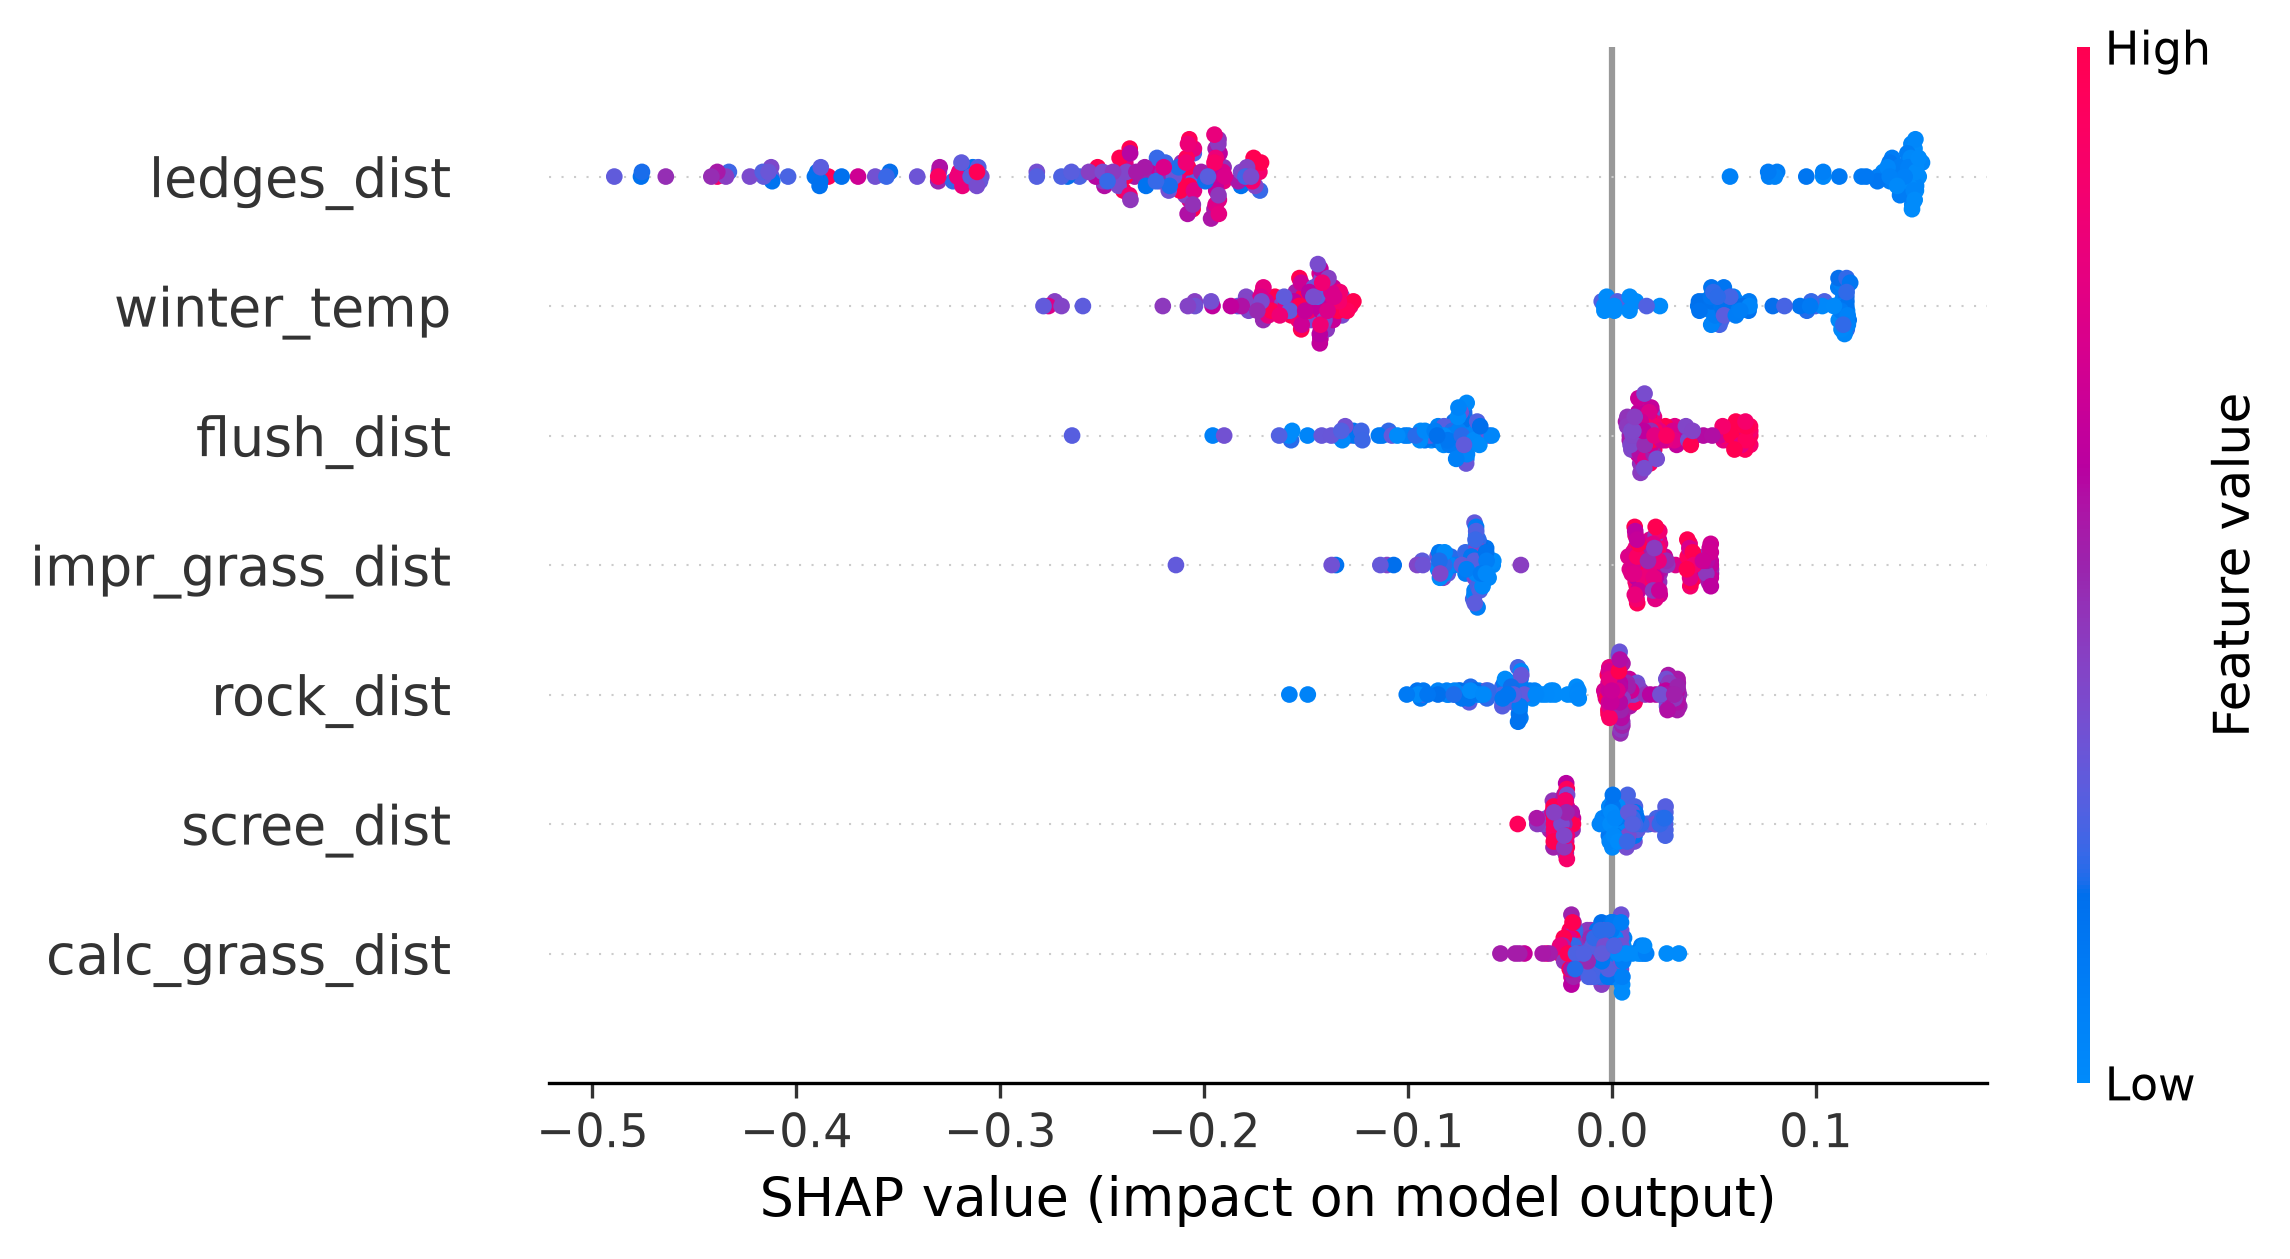

ledges_dist        0.2322
winter_temp        0.1196
flush_dist         0.0598
impr_grass_dist    0.0472
rock_dist          0.0316
scree_dist         0.0139
calc_grass_dist    0.0109
Name: mean_abs_shap, dtype: float64

In [11]:
shap_gdf = pandas.concat(
    [train_pres_gdf, train_gdf[train_gdf["clsid"] == 0].sample(n=177, random_state=42)]
)
if importlib.util.find_spec("shap") is not None:
    species_distribution.shap_sklearn_mdl_explainer(
        est_cls_obj=rf_mdl,
        train_vec_file=shap_gdf,
        train_vec_lyr=None,
        analysis_vars=analysis_vars,
        shap_summary_plot=os.path.join(plots_dir, "rf_shap_summary.png"),
        shap_scatter_plots_dir=os.path.join(plots_dir, "rf_shap_scatter"),
        use_tree_explainer=True,
    )
    display(Image(filename=os.path.join(plots_dir, "rf_shap_summary.png"), width=650))

    import shap

    tree_shap = shap.TreeExplainer(rf_mdl)(shap_gdf[analysis_vars])
    rf_shap_df = pandas.Series(
        numpy.abs(tree_shap.values[:, :, 1]).mean(axis=0), index=analysis_vars, name="mean_abs_shap"
    )
    display(rf_shap_df.sort_values(ascending=False).round(4))
else:
    print("The shap package is not installed, so the SHAP analysis is skipped.")

The ranking is the same as for the other models: distance to ledges (mean |SHAP| 0.23) and winter temperature (0.12) far ahead, then flushes (0.06) and improved grassland (0.05). Every variable gets some credit, because the forest uses all of them in its splits. The scatter plots (in `outputs/sdm_RF_outs/plots/rf_shap_scatter/`) show the steps of the response curves, with a vertical spread at each value caused by the interactions the trees have learnt.

### 4.4 Sobol Sensitivity Analysis

In [12]:
if importlib.util.find_spec("SALib") is not None:
    rf_total_si, rf_first_si, rf_second_si = species_distribution.salib_sklearn_mdl_sensitivity(
        est_cls_obj=rf_mdl,
        train_vec_file=train_gdf,
        train_vec_lyr=None,
        analysis_vars=analysis_vars,
        n_samples=1024,
        sobol_overall_file=os.path.join(out_dir, "rf_sobol_total.csv"),
        sobol_first_file=os.path.join(out_dir, "rf_sobol_first_order.csv"),
        sobol_second_file=os.path.join(out_dir, "rf_sobol_second_order.csv"),
        rnd_seed=42,
    )
    order = rf_total_si["ST"].sort_values(ascending=False).index
    display(pandas.concat([rf_total_si, rf_first_si], axis=1).loc[order].round(3))
    print("Largest second order (pairwise interaction) indices:")
    display(rf_second_si.sort_values("S2", ascending=False).head(5).round(3))
else:
    print("The SALib package is not installed, so the Sobol analysis is skipped.")

calc_grass_dist Range:	(0.0 - 6102.75341796875)
flush_dist Range:	(0.0 - 2214.497802734375)
impr_grass_dist Range:	(0.0 - 3739.732666015625)
ledges_dist Range:	(0.0 - 5341.947265625)
rock_dist Range:	(0.0 - 6917.6005859375)
scree_dist Range:	(0.0 - 3493.13623046875)
winter_temp Range:	(2.5071563720703125 - 4.4408345222473145)


,ST,ST_conf,S1,S1_conf
variable,,,,
ledges_dist,0.799,0.115,0.583,0.109
winter_temp,0.332,0.066,0.172,0.049
impr_grass_dist,0.046,0.012,0.009,0.010
flush_dist,0.039,0.014,0.013,0.011
rock_dist,0.017,0.005,0.006,0.007
calc_grass_dist,0.007,0.001,0.004,0.008
scree_dist,0.006,0.001,0.009,0.008


Largest second order (pairwise interaction) indices:


,,S2,S2_conf
variable_1,variable_2,,
ledges_dist,winter_temp,0.190,0.245
impr_grass_dist,ledges_dist,0.027,0.046
flush_dist,ledges_dist,0.015,0.033
impr_grass_dist,winter_temp,0.014,0.019
ledges_dist,scree_dist,0.013,0.175


The distance to ledges (ST 0.80, S1 0.58) and winter temperature (ST 0.33, S1 0.17) dominate, as in the other models, and they interact (S2 = 0.19, with a very wide interval of ±0.25). Here the interaction can be real model structure (trees that split on temperature and then on ledges) as well as an effect of the bounded output; the confidence interval of the S2 index is too wide to tell. The other five variables each have ST of about 0.01–0.05. The CSV files of the analysis (`rf_sobol_total.csv`, `rf_sobol_first_order.csv` and `rf_sobol_second_order.csv`) are read by notebook 05.

## 5. Predict the Random Forest Suitability Map

In [13]:
rf_prob_img = os.path.join(out_dir, "Snowdon_Beetle_rf_sdm_prob.tif")
species_distribution.pred_ensemble_sklearn_mdls_prob(
    rf_mdls, valid_msk_img, 1, env_vars, analysis_vars, rf_prob_img,
    gdalformat="GTIFF", calc_stats=True, uncertainty=["std", "iqr"], use_pbar=False,
)
ens_train_probs = numpy.median(
    [species_distribution.get_positive_class_probs(mdl, train_gdf[analysis_vars]) for mdl in rf_mdls],
    axis=0,
)
rf_thres = {
    "max TSS": species_distribution.calc_binary_threshold(test_y, ens_test_probs, method="max_tss"),
    "10th percentile training presence": float(
        numpy.percentile(ens_train_probs[train_gdf["clsid"] == 1], 10)
    ),
}
with rasterio.open(rf_prob_img) as src:
    rf_prob_arr = src.read(1)
    pxl_km2 = abs(src.res[0] * src.res[1]) / 1e6
valid = rf_prob_arr >= 0
thres_rows = []
for name, thres in rf_thres.items():
    test_bin = (ens_test_probs >= thres).astype(int)
    thres_rows.append({
        "threshold": name, "value": thres,
        "test sensitivity": test_bin[test_y == 1].mean(),
        "test specificity": 1 - test_bin[test_y == 0].mean(),
        "suitable area (km²)": (rf_prob_arr[valid] >= thres).sum() * pxl_km2,
        "% of study area": 100 * (rf_prob_arr[valid] >= thres).mean(),
    })
display(pandas.DataFrame(thres_rows).round(3))
rf_boyce = species_distribution.calc_boyce_index_from_raster(
    rf_prob_img, presences_vec_file, presences_vec_lyr, use_pbar=False
)
print(f"Boyce index of the map: {rf_boyce['boyce']:.3f}")

rf_bin_img = os.path.join(out_dir, "Snowdon_Beetle_rf_sdm_bin.tif")
rsgispy.imagecalc.maths.band_maths(
    rf_bin_img,
    f"prob < 0 ? 255 : (prob >= {rf_thres['max TSS']} ? 1 : 0)",
    [rsgispy.imagecalc.maths.BandDefn("prob", rf_prob_img, 1)],
    gdalformat="GTIFF", datatype=rsgispy.TYPE_8UINT, no_data_val=255, use_pbar=False,
)

,threshold,value,test sensitivity,test specificity,suitable area (km²),% of study area
0,max TSS,0.482,1.000,0.906,16.582,9.744
1,10th percentile training presence,0.814,0.727,0.967,5.500,3.232


Boyce index of the map: 0.797


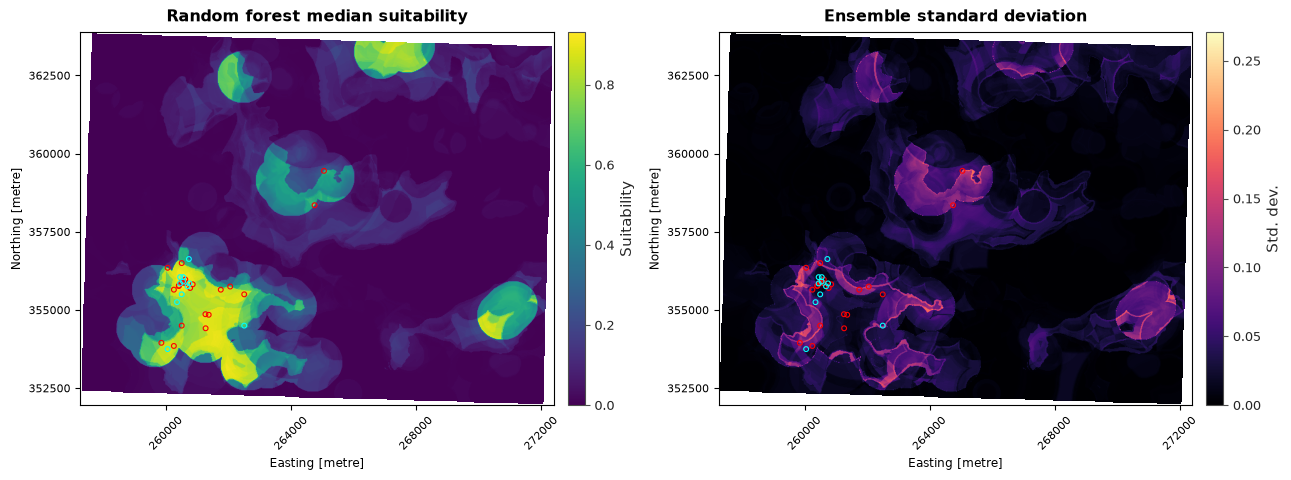

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, (band, title, cmap, label) in zip(
    axs, [(1, "Random forest median suitability", "viridis", "Suitability"),
          (2, "Ensemble standard deviation", "magma", "Std. dev.")]
):
    rsgispy.mapping.raster.create_raster_cmap_img_map(
        ax, input_img=rf_prob_img, img_band=band, title_str=title, cmap_name=cmap,
        show_colour_bar=True, cbar_label=label, show_scale_bar=False,
    )
    train_pres_gdf.plot(ax=ax, facecolor="none", edgecolor="red", markersize=12, linewidth=0.8)
    test_gdf[test_gdf["clsid"] == 1].plot(ax=ax, facecolor="none", edgecolor="cyan", markersize=12, linewidth=0.8)
    ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()

The random forest predicts the same main areas as the logistic regression (Yr Wyddfa, and patches in the centre, the north and the east), with sharp, often circular, edges: these are the steps of the distance responses (e.g. the cliff about 780 m from a ledge) drawn on the map. The ensemble standard deviation is highest along these edges, where the members put their steps in slightly different places.

The two thresholds are very different. The maximum-TSS threshold of the test points (0.482) predicts 16.6 km² (9.7 %) suitable, with all 11 test presences inside it. The 10th percentile training presence threshold is 0.814 and predicts only 5.5 km², missing 3 of the 11 test presences (sensitivity 0.727). The reason is over-fitting: the forest predicts its own training presences with higher values than new sites (training AUC 0.989), so **a threshold calculated from the training predictions of a flexible model is too high**. Always choose the threshold from independent (test or out-of-fold) predictions for such models. The Boyce index of the map is 0.797.

## 6. Projecting to a Warmer Climate

The same +0.5 °C and +1 °C scenarios as notebooks 02 and 03 (see notebook 02, section 16, for why these are large changes with this temperature raster). Like MaxEnt's clamping, a random forest predicts beyond the training range as if the variable were at the end of its range (no tree has a split beyond it).

In [15]:
scen_rows = []
for warming in [0.5, 1.0]:
    tag = f"plus{warming:.1f}".replace(".", "_")
    warm_env_vars = species_distribution.copy_env_vars_for_scenario(
        env_vars, {"winter_temp": os.path.join(lr_dir, f"Mean_Winter_Temp_{tag}.tif")}
    )
    warm_prob_img = os.path.join(out_dir, f"Snowdon_Beetle_rf_sdm_prob_{tag}.tif")
    species_distribution.pred_ensemble_sklearn_mdls_prob(
        rf_mdls, valid_msk_img, 1, warm_env_vars, analysis_vars, warm_prob_img,
        calc_stats=True, use_pbar=False,
    )
    warm_bin_img = os.path.join(out_dir, f"Snowdon_Beetle_rf_sdm_bin_{tag}.tif")
    rsgispy.imagecalc.maths.band_maths(
        warm_bin_img,
        f"prob < 0 ? 255 : (prob >= {rf_thres['max TSS']} ? 1 : 0)",
        [rsgispy.imagecalc.maths.BandDefn("prob", warm_prob_img, 1)],
        gdalformat="GTIFF", datatype=rsgispy.TYPE_8UINT, no_data_val=255, use_pbar=False,
    )
    summary = species_distribution.calc_range_change(
        rf_bin_img, warm_bin_img, os.path.join(out_dir, f"rf_range_change_{tag}.tif"),
        in_msk_img=valid_msk_img, use_pbar=False,
    )
    scen_rows.append(
        {
            "warming (°C)": warming,
            "current (km²)": summary["current_area"] / 1e6,
            "scenario (km²)": summary["future_area"] / 1e6,
            "lost (km²)": summary["area_lost"] / 1e6,
            "gained (km²)": summary["area_gained"] / 1e6,
            "stable (km²)": summary["area_stable"] / 1e6,
            "net change (%)": summary["pct_net_change"],
        }
    )
scen_df = pandas.DataFrame(scen_rows)
scen_df.round(2)

,warming (°C),current (km²),scenario (km²),lost (km²),gained (km²),stable (km²),net change (%)
0,0.5,16.58,1.18,15.40,0.0,1.18,-92.88
1,1.0,16.58,0.00,16.58,0.0,0.00,-100.00


The random forest loses almost all its suitable area at +0.5 °C (16.6 km² → 1.2 km², −93 %), and all of it at +1 °C, like the logistic regression (−89 % and −100 %) and more than MaxEnt at +0.5 °C (−64 %).

The reason is the warm side of its temperature response: beyond the warmest training presence (3.05 °C) the forest predicts a flat 0.33 from temperature, and its maximum-TSS threshold is 0.482, so warming takes most pixels below the threshold. Unlike MaxEnt, its cold-side step is small (0.79 below 2.69 °C), so the coldest ground was already suitable today and there is nothing to gain. The forest does not "know" that warmer means worse beyond the presences' range; it only knows that the presences are not there, and with a lower threshold (as for a less smooth forest) part of the area could stay above it whatever the temperature. Notebook 05 compares the three projections.

## 7. Save the Results for the Comparison

In [16]:
rsgispy.tools.jsonio.write_dict_to_json(
    {key: float(val) for key, val in rf_metrics.items()}, os.path.join(out_dir, "rf_test_metrics.json")
)
rsgispy.tools.jsonio.write_dict_to_json(rf_thres, os.path.join(out_dir, "rf_thresholds.json"))
pandas.DataFrame({"clsid": test_y, "ens_prob": ens_test_probs}).to_csv(
    os.path.join(out_dir, "rf_test_scores.csv"), index=False
)
rf_scores_df.to_csv(os.path.join(out_dir, "rf_spatial_cv_scores.csv"), index=False)
scen_df.to_csv(os.path.join(out_dir, "rf_scenarios.csv"), index=False)
if importlib.util.find_spec("shap") is not None:
    rf_shap_df.to_csv(os.path.join(out_dir, "rf_shap_mean_abs.csv"), index_label="variable")
sorted(os.listdir(out_dir))

['Snowdon_Beetle_rf_sdm_bin.tif',
 'Snowdon_Beetle_rf_sdm_bin_plus0_5.tif',
 'Snowdon_Beetle_rf_sdm_bin_plus1_0.tif',
 'Snowdon_Beetle_rf_sdm_prob.tif',
 'Snowdon_Beetle_rf_sdm_prob_plus0_5.tif',
 'Snowdon_Beetle_rf_sdm_prob_plus1_0.tif',
 'plots',
 'rf_jackknife_var_importance.csv',
 'rf_params.json',
 'rf_range_change_plus0_5.tif',
 'rf_range_change_plus1_0.tif',
 'rf_response_curves.csv',
 'rf_scenarios.csv',
 'rf_shap_mean_abs.csv',
 'rf_sobol_first_order.csv',
 'rf_sobol_second_order.csv',
 'rf_sobol_total.csv',
 'rf_spatial_cv_scores.csv',
 'rf_test_metrics.json',
 'rf_test_scores.csv',
 'rf_thresholds.json']